In [1]:
%pip install -q --no-deps facenet-pytorch


In [2]:

import torch
import torchvision
import PIL
import pandas as pd
import numpy as np
import sklearn

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Pillow:", PIL.__version__)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("GPU available:", torch.cuda.is_available())

from facenet_pytorch import InceptionResnetV1

print("FaceNet import successful!")


PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
Pillow: 11.3.0
Pandas: 2.2.3
NumPy: 2.1.3
Scikit-learn: 1.6.1
GPU available: True
FaceNet import successful!


In [3]:
import os, random, json, platform
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import torch
from PIL import Image
from pathlib import Path
from sklearn.datasets import fetch_lfw_people
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, roc_auc_score
from facenet_pytorch import InceptionResnetV1
from tqdm.auto import tqdm
SEED=228
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic=True; torch.backends.cudnn.benchmark=False
DEVICE='cuda' if torch.cuda.is_available() else 'cpu'
OUT=Path('results'); OUT.mkdir(exist_ok=True)
print('Device:', DEVICE, 'PyTorch:', torch.__version__, 'Python:', platform.python_version())

Device: cuda PyTorch: 2.11.0+cu130 Python: 3.13.16


Dataset downloaded successfully!
Total images: 4324
Total identities: 158
Image shape: (62, 47, 3)


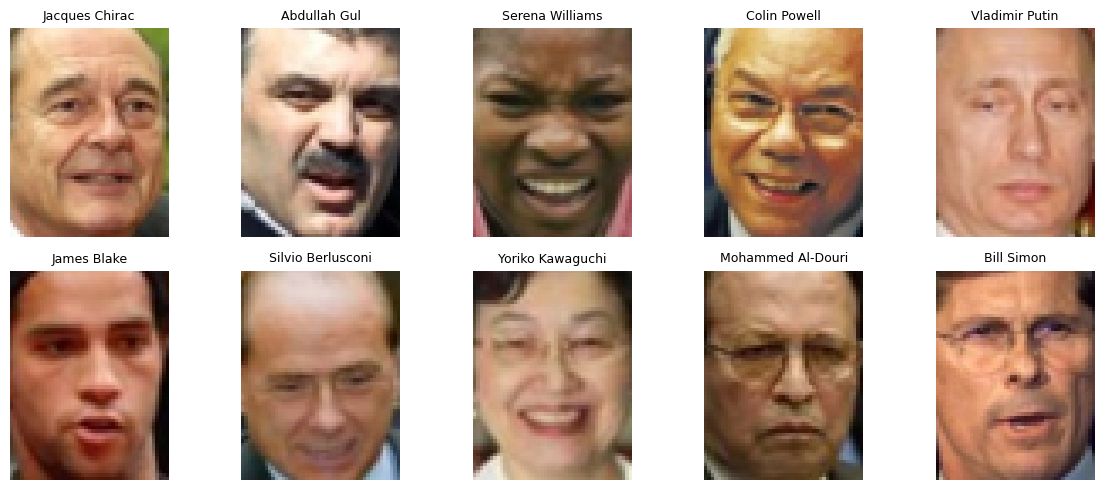

In [4]:

from sklearn.datasets import fetch_lfw_people
import numpy as np
import matplotlib.pyplot as plt

# Download and load LFW automatically
lfw = fetch_lfw_people(
    data_home="/content/lfw_data",
    min_faces_per_person=10,
    resize=0.5,
    color=True,
    download_if_missing=True
)

images = lfw.images
labels = lfw.target
names = lfw.target_names

print("Dataset downloaded successfully!")
print("Total images:", len(images))
print("Total identities:", len(names))
print("Image shape:", images.shape[1:])

# Display sample faces
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for ax, idx in zip(axes.flat, range(min(10, len(images)))):
    ax.imshow(images[idx] / 255.0 if images[idx].max() > 1 else images[idx])
    ax.set_title(names[labels[idx]], fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [5]:
MIN_FACES=10
lfw=fetch_lfw_people(min_faces_per_person=MIN_FACES, resize=1.0, color=True, download_if_missing=True)
images=lfw.images; labels=lfw.target.astype(int); names=lfw.target_names
print('Shape:', images.shape, 'Identities:', len(names), 'Images:', len(images))
assert len(images)==len(labels)
assert np.isfinite(images).all()
counts=pd.Series(labels).value_counts().sort_index()
print('Per identity min/median/max:', counts.min(), counts.median(), counts.max())
print('Exact image duplicates:', pd.DataFrame(images.reshape(len(images),-1)).duplicated().sum())
print('Pixel range:', float(images.min()), float(images.max()))
print('Image shape:', images.shape[1:])

Shape: (4324, 125, 94, 3) Identities: 158 Images: 4324
Per identity min/median/max: 10 17.0 530
Exact image duplicates: 0
Pixel range: 0.0 1.0
Image shape: (125, 94, 3)


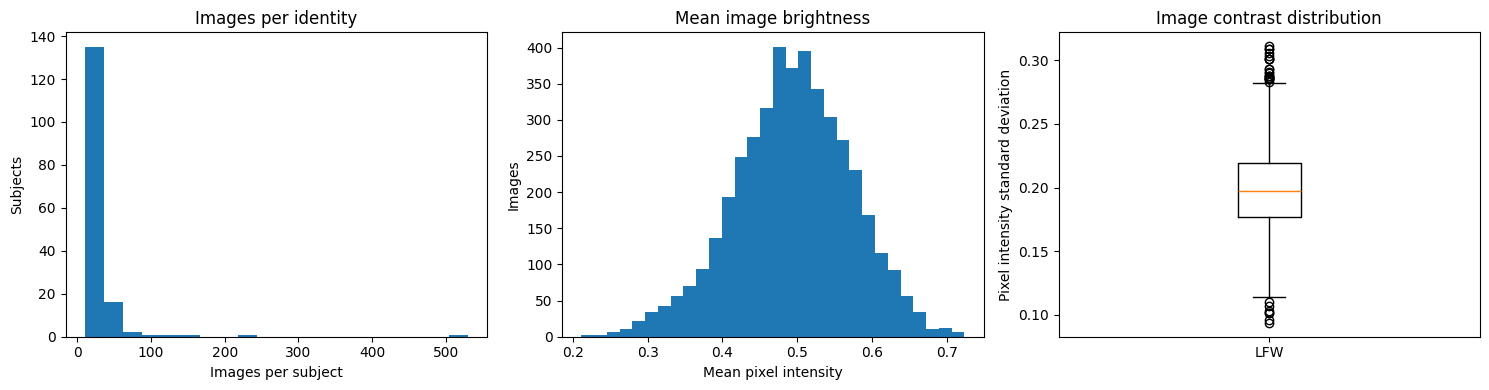

Figure 1: Shows class imbalance and variation in brightness and contrast that may affect matching.


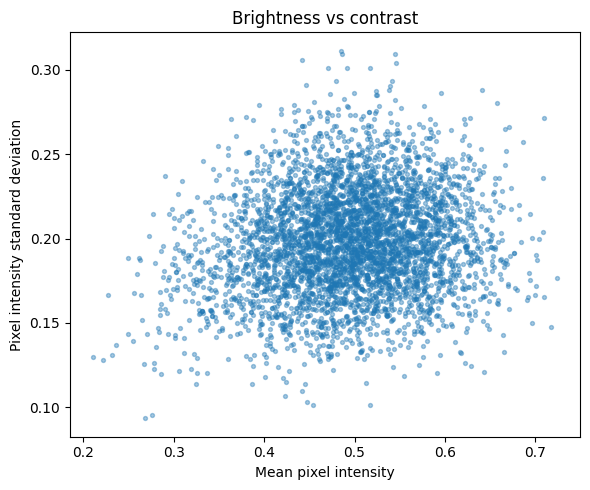

Figure 2: Shows the relationship between image brightness and contrast.


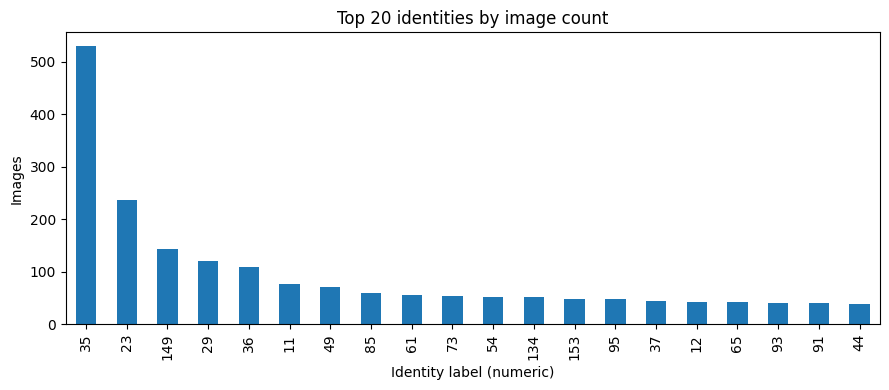

Figure 3: Shows identity imbalance and motivates identity-balanced pair sampling.


In [6]:
fig,axs=plt.subplots(1,3,figsize=(15,4))
axs[0].hist(counts.values,bins=20); axs[0].set(title='Images per identity',xlabel='Images per subject',ylabel='Subjects')
brightness=images.mean(axis=(1,2,3)); contrast=images.std(axis=(1,2,3))
axs[1].hist(brightness,bins=30); axs[1].set(title='Mean image brightness',xlabel='Mean pixel intensity',ylabel='Images')
axs[2].boxplot(contrast); axs[2].set(title='Image contrast distribution',ylabel='Pixel intensity standard deviation',xticks=[1],xticklabels=['LFW'])
plt.tight_layout(); plt.savefig(OUT/'eda_univariate.png',dpi=180); plt.show()
print('Figure 1: Shows class imbalance and variation in brightness and contrast that may affect matching.')
fig,ax=plt.subplots(figsize=(6,5)); ax.scatter(brightness,contrast,s=8,alpha=.4); ax.set(title='Brightness vs contrast',xlabel='Mean pixel intensity',ylabel='Pixel intensity standard deviation'); plt.tight_layout(); plt.savefig(OUT/'eda_bivariate.png',dpi=180); plt.show()
print('Figure 2: Shows the relationship between image brightness and contrast.')
fig,ax=plt.subplots(figsize=(9,4)); counts.sort_values(ascending=False).head(20).plot.bar(ax=ax); ax.set(title='Top 20 identities by image count',xlabel='Identity label (numeric)',ylabel='Images'); plt.tight_layout(); plt.savefig(OUT/'eda_class_balance.png',dpi=180); plt.show()
print('Figure 3: Shows identity imbalance and motivates identity-balanced pair sampling.')

In [7]:
import torch.nn.functional as F
model=InceptionResnetV1(pretrained='vggface2').eval().to(DEVICE)
@torch.no_grad()
def embed_batch(arr):
    x=torch.from_numpy(arr).permute(0,3,1,2).float().to(DEVICE)
    if x.max()<=1.01: x=x*255.0
    x=F.interpolate(x,size=(160,160),mode='bilinear',align_corners=False)
    x=(x-127.5)/128.0
    z=model(x)
    return F.normalize(z,dim=1).cpu().numpy()
emb=np.concatenate([embed_batch(images[i:i+32]) for i in tqdm(range(0,len(images),32))],axis=0)
assert emb.shape==(len(images),512)
np.save(OUT/'embeddings.npy',emb)
print('Embeddings:',emb.shape)

  0%|          | 0.00/107M [00:00<?, ?B/s]

  0%|          | 0/136 [00:00<?, ?it/s]

Embeddings: (4324, 512)


In [8]:
unique_ids=np.unique(labels)
val_ids,test_ids=train_test_split(unique_ids,test_size=.5,random_state=SEED)
rng=np.random.default_rng(SEED)
def make_pairs(ids, max_genuine=1500):
    templates={}; genuine=[]; impostor=[]
    for identity in ids:
        ix=np.flatnonzero(labels==identity)
        ix=rng.permutation(ix)
        templates[int(identity)]=emb[ix[0]]
        for j in ix[1:]: genuine.append((int(identity),int(j)))
    if len(genuine)>max_genuine:
        chosen=rng.choice(len(genuine),max_genuine,replace=False)
        genuine=[genuine[i] for i in chosen]
    for identity,j in genuine:
        others=ids[ids!=identity]
        other=int(rng.choice(others))
        impostor.append((other,j))
    pairs=genuine+impostor
    y=np.array([1]*len(genuine)+[0]*len(impostor))
    scores=np.array([float(templates[t]@emb[j]) for t,j in pairs])
    return y,scores,pairs
val_y,val_s,val_pairs=make_pairs(val_ids)
test_y,test_s,test_pairs=make_pairs(test_ids)
print('Validation identities/trials:',len(val_ids),len(val_y),'Test identities/trials:',len(test_ids),len(test_y))
print('Validation genuine/impostor:',np.bincount(val_y),'Test genuine/impostor:',np.bincount(test_y))

Validation identities/trials: 79 3000 Test identities/trials: 79 3000
Validation genuine/impostor: [1500 1500] Test genuine/impostor: [1500 1500]


In [9]:
def threshold_table(y,s):
    thresholds=np.unique(np.r_[-1.01,s,1.01])
    pos=int((y==1).sum()); neg=int((y==0).sum())
    rows=[]
    for t in thresholds:
        pred=s>=t
        fa=int(((y==0)&pred).sum()); fr=int(((y==1)&(~pred)).sum())
        rows.append((t,fa,neg,fr,pos,fa/neg,fr/pos))
    return pd.DataFrame(rows,columns=['threshold','FA','impostor_count','FR','genuine_count','FAR','FRR'])
vt=threshold_table(val_y,val_s)
ix=(vt.FAR-vt.FRR).abs().idxmin(); threshold=float(vt.loc[ix,'threshold'])
print('Validation operating threshold:',threshold)
print('Validation near-EER FAR/FRR:',float(vt.loc[ix,'FAR']),float(vt.loc[ix,'FRR']))
tt=threshold_table(test_y,test_s)
pred=test_s>=threshold
FA=int(((test_y==0)&pred).sum()); TN=int(((test_y==0)&(~pred)).sum())
FR=int(((test_y==1)&(~pred)).sum()); TA=int(((test_y==1)&pred).sum())
far=FA/(FA+TN); frr=FR/(FR+TA)
fpr,tpr,roc_t=roc_curve(test_y,test_s)
fnr=1-tpr; eer_idx=np.argmin(np.abs(fpr-fnr)); eer=float((fpr[eer_idx]+fnr[eer_idx])/2)
metrics={'seed':SEED,'dataset':'LFW','min_faces_per_person':MIN_FACES,'encoder':'facenet-pytorch InceptionResnetV1 pretrained vggface2','val_identities':len(val_ids),'test_identities':len(test_ids),'val_genuine':int(val_y.sum()),'val_impostor':int((val_y==0).sum()),'test_genuine':int(test_y.sum()),'test_impostor':int((test_y==0).sum()),'threshold_from_validation':threshold,'false_acceptances':FA,'impostor_trials':FA+TN,'false_rejections':FR,'genuine_trials':FR+TA,'FAR':far,'FRR':frr,'test_EER':eer,'test_ROC_AUC':float(roc_auc_score(test_y,test_s))}
(OUT/'metrics.json').write_text(json.dumps(metrics,indent=2))
print(json.dumps(metrics,indent=2))

Validation operating threshold: 0.4868399500846863
Validation near-EER FAR/FRR: 0.01 0.01
{
  "seed": 228,
  "dataset": "LFW",
  "min_faces_per_person": 10,
  "encoder": "facenet-pytorch InceptionResnetV1 pretrained vggface2",
  "val_identities": 79,
  "test_identities": 79,
  "val_genuine": 1500,
  "val_impostor": 1500,
  "test_genuine": 1500,
  "test_impostor": 1500,
  "threshold_from_validation": 0.4868399500846863,
  "false_acceptances": 7,
  "impostor_trials": 1500,
  "false_rejections": 75,
  "genuine_trials": 1500,
  "FAR": 0.004666666666666667,
  "FRR": 0.05,
  "test_EER": 0.022999999999999993,
  "test_ROC_AUC": 0.9969586666666665
}


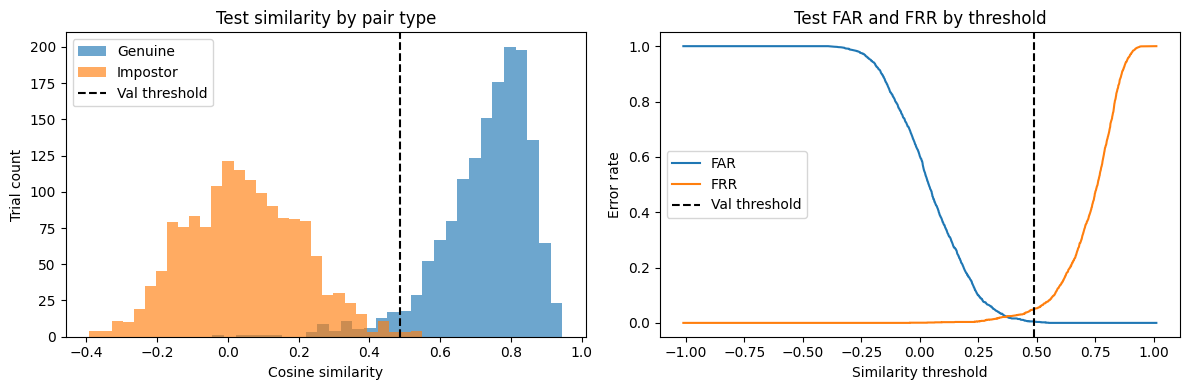

Figure 4: Shows genuine/impostor score overlap and the security–usability threshold tradeoff.


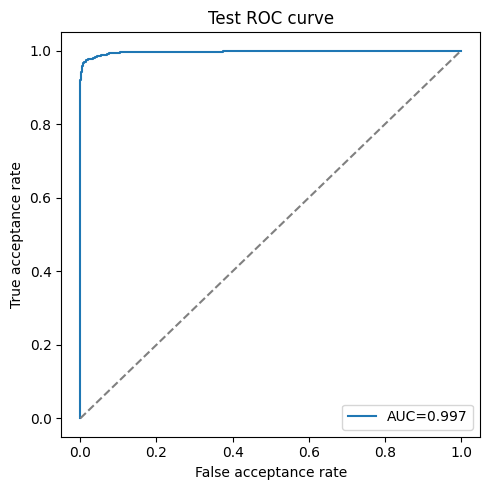

Figure 5: Shows biometric discrimination across operating thresholds.


In [10]:
fig,axs=plt.subplots(1,2,figsize=(12,4))
axs[0].hist(test_s[test_y==1],bins=30,alpha=.65,label='Genuine'); axs[0].hist(test_s[test_y==0],bins=30,alpha=.65,label='Impostor'); axs[0].axvline(threshold,color='black',linestyle='--',label='Val threshold'); axs[0].set(title='Test similarity by pair type',xlabel='Cosine similarity',ylabel='Trial count'); axs[0].legend()
axs[1].plot(tt.threshold,tt.FAR,label='FAR'); axs[1].plot(tt.threshold,tt.FRR,label='FRR'); axs[1].axvline(threshold,color='black',linestyle='--',label='Val threshold'); axs[1].set(title='Test FAR and FRR by threshold',xlabel='Similarity threshold',ylabel='Error rate'); axs[1].legend()
plt.tight_layout(); plt.savefig(OUT/'baseline_thresholds.png',dpi=180); plt.show()
print('Figure 4: Shows genuine/impostor score overlap and the security–usability threshold tradeoff.')
fig,ax=plt.subplots(figsize=(5,5)); ax.plot(fpr,tpr,label=f'AUC={metrics["test_ROC_AUC"]:.3f}'); ax.plot([0,1],[0,1],'--',color='gray'); ax.set(title='Test ROC curve',xlabel='False acceptance rate',ylabel='True acceptance rate'); ax.legend(); plt.tight_layout(); plt.savefig(OUT/'baseline_roc.png',dpi=180); plt.show()
print('Figure 5: Shows biometric discrimination across operating thresholds.')

In [11]:
false_accept_ix=np.flatnonzero((test_y==0)&pred)
false_reject_ix=np.flatnonzero((test_y==1)&(~pred))
print('False accepts:',len(false_accept_ix),'False rejects:',len(false_reject_ix))
print('Highest-scoring false accepts:',sorted([(round(float(test_s[i]),4),test_pairs[i]) for i in false_accept_ix],reverse=True)[:5])
print('Lowest-scoring false rejects:',sorted([(round(float(test_s[i]),4),test_pairs[i]) for i in false_reject_ix])[:5])
print('Hypotheses to check: poor crop alignment, pose/illumination, low resolution, and identity similarity.')
print('Report exact measured values from results/metrics.json. Do not replace with estimates.')

False accepts: 7 False rejects: 75
Highest-scoring false accepts: [(0.5496, (78, 3397)), (0.538, (0, 3617)), (0.5367, (48, 1785)), (0.5187, (78, 3296)), (0.5125, (153, 1512))]
Lowest-scoring false rejects: [(-0.0439, (112, 759)), (0.0315, (9, 713)), (0.0628, (112, 2519)), (0.0935, (156, 1098)), (0.1473, (97, 1222))]
Hypotheses to check: poor crop alignment, pose/illumination, low resolution, and identity similarity.
Report exact measured values from results/metrics.json. Do not replace with estimates.
